In [1]:
   import matplotlib.pyplot as plt
   import numpy as np
   import pandas as pd
   import statsmodels.formula.api as smf

   from analytics.db import query
   from analytics.paths import FIGURES, RAW_WEB

In [2]:
query("""
      --w15
SELECT
    EXTRACT(HOUR FROM order_purchase_timestamp) AS hour,
    COUNT(*) AS total_orders
FROM clean.orders
GROUP BY hour
ORDER BY total_orders DESC
LIMIT 3;
      
      """)

,hour,total_orders
0,16.0,6675
1,11.0,6578
2,14.0,6569


## Part 0 — One row for each order

In [3]:

joined = query("""
    SELECT o.order_id, r.review_score
    FROM clean.orders AS o
    JOIN clean.order_reviews AS r ON r.order_id = o.order_id
    WHERE o.order_delivered_customer_date IS NOT NULL
""")

len(joined), joined["order_id"].nunique()


(96359, 95830)


### Step 1 — Joining orders and reviews

I joined the orders table with the order_reviews table using order_id and kept only delivered orders. The result contains 96,359 rows but only 95,830 unique orders. This difference means that some orders have multiple reviews, causing duplicate order_id values after the join. Therefore, the number of rows is not always equal to the number of unique orders.


In [4]:

orders = query("""
    WITH latest AS (
        SELECT order_id, review_score,
               ROW_NUMBER() OVER (
                   PARTITION BY order_id
                   ORDER BY review_creation_date DESC, review_answer_timestamp DESC, review_id
               ) AS n
        FROM clean.order_reviews
    ),
    items AS (
        SELECT order_id, COUNT(*) AS items, SUM(freight_value) AS freight
        FROM clean.order_items
        GROUP BY order_id
    )
    SELECT o.order_id, c.customer_state AS state,
           o.order_purchase_timestamp AS purchased,
           o.order_delivered_customer_date AS delivered,
           o.order_estimated_delivery_date AS estimated,
           r.review_score AS score, i.items, i.freight
    FROM clean.orders AS o
    JOIN clean.customers AS c ON c.customer_id = o.customer_id
    JOIN latest AS r ON r.order_id = o.order_id AND r.n = 1
    JOIN items AS i ON i.order_id = o.order_id
    WHERE o.order_delivered_customer_date IS NOT NULL
    ORDER BY o.order_id
""")

len(orders), orders["order_id"].nunique()


(95830, 95830)


### Step 2 — Building one row per order

I created two CTEs. The first one uses ROW_NUMBER() to identify the latest review for each order, while the second one calculates the number of items and total freight for each order. I then joined these results with orders and customers, keeping only the latest review (n = 1) and delivered orders. The final dataset contains 95,830 rows and 95,830 unique orders, confirming that each order appears exactly once.


In [5]:

orders["days"] = (orders["delivered"] - orders["purchased"]).dt.total_seconds() / 86400

orders["late"] = orders["delivered"].dt.normalize() > orders["estimated"].dt.normalize()

orders.groupby("late")["score"].agg(["size", "mean"]).round(2)


,size,mean
late,,
False,89448,4.29
True,6382,2.27



### Step 3 — Delivery days and late orders

I calculated the delivery duration in days by subtracting the purchase timestamp from the delivery timestamp. I then created a boolean column called late to identify orders delivered after their estimated delivery date. Finally, I grouped orders by their late status and calculated the number of orders and average review score. Late orders had an average score of 2.27, compared with 4.29 for orders delivered on time or earlier.


In [6]:
#0.a

joined.groupby("order_id").size().gt(1).sum()


np.int64(525)

In [7]:
#0.a

joined_late = joined.merge(
    orders[["order_id", "late"]],
    on="order_id",
    how="left"
)

joined_late.groupby("late")["review_score"].agg(["size", "mean"]).round(2)


,size,mean
late,,
False,89949,4.29
True,6410,2.27



### Exercise 0.a — Multiple reviews

I counted the orders with more than one review and merged the late status into the original joined dataset. Since some orders have multiple reviews, they appear more than once and receive more weight in the average score calculation. Therefore, the averages may differ from Step 3, where each order appears exactly once.


## Part 1 — Correlation: what moves with the stars?

In [8]:

toy = pd.DataFrame({"days": [5, 10, 15, 20], "stars": [5, 4, 4, 3]})

round(toy["days"].corr(toy["stars"]), 2)


np.float64(-0.95)


### Step 1 — Understanding correlation

I created a small example dataset with delivery days and customer ratings. I used the corr() method to calculate the correlation between the two columns. The result was -0.95, indicating a strong negative linear relationship: as delivery days increase, customer ratings tend to decrease.


In [9]:

orders[["score", "days", "late", "items", "freight"]].corr()["score"].round(2)


score      1.00
days      -0.33
late      -0.39
items     -0.12
freight   -0.09
Name: score, dtype: float64


### Step 2 — Correlation with customer ratings

I calculated the correlation between customer ratings and four order-related variables. Late deliveries had the strongest negative correlation with review scores (-0.39), followed by delivery days (-0.33). The number of items (-0.12) and freight cost (-0.09) had much weaker negative correlations. These results show associations, not necessarily causal relationships.



### Step 3 — Interpreting correlations

Late deliveries have the strongest negative correlation with customer ratings (-0.39), making them the most important factor to investigate among the four variables. However, correlation does not imply causation. Other factors, such as delivery distance or location, may influence both delivery delays and customer satisfaction. Therefore, we should investigate these relationships further before making business decisions.


In [10]:

anscombe = pd.read_csv(RAW_WEB / "seaborn" / "anscombe.csv")

anscombe.groupby("dataset").apply(lambda d: d["x"].corr(d["y"])).round(2)


dataset
I      0.82
II     0.82
III    0.82
IV     0.82
dtype: float64


### Step 4 — Anscombe's quartet

I loaded Anscombe's quartet dataset and calculated the correlation between x and y for each dataset. All four datasets have approximately the same correlation (0.82), despite having very different distributions and patterns. This demonstrates that correlation alone does not describe the full relationship between two variables. Visualizing data is important to identify nonlinear patterns and outliers.


In [11]:
#1.a

orders[orders["items"].isin([1, 2, 3, 4])].groupby("items")["score"].agg(["size", "mean"]).round(2)


,size,mean
items,,
1,86301,4.21
2,7320,3.69
3,1286,3.53
4,487,3.38


In [12]:
#1.a

orders[orders["items"].isin([1, 2, 3, 4])].groupby("items").agg(
    orders=("order_id", "size"),
    avg_score=("score", "mean"),
    avg_days=("days", "mean"),
    late_rate=("late", "mean"),
    avg_freight=("freight", "mean")
).round(2)


,orders,avg_score,avg_days,late_rate,avg_freight
items,,,,,
1,86301,4.21,12.60,0.07,20.32
2,7320,3.69,11.78,0.05,37.06
3,1286,3.53,11.58,0.05,54.84
4,487,3.38,12.12,0.04,74.17



### Exercise 1.a — Number of items and customer ratings

I calculated the average review score for orders containing one, two, three, and four items. The correlation between the number of items and review scores is weakly negative (-0.12).

One possible explanation is that larger orders may take longer to deliver, experience more delays, or have higher freight costs. To investigate this hypothesis, I compared average delivery days, late delivery rates, and average freight costs across orders with different item counts.

The results help us investigate possible explanations, but they do not prove that having more items causes lower customer ratings.


## Part 2 — A regression line: what one day costs


In [13]:
toy_model = smf.ols("stars ~ days", data=toy).fit()
toy_model.params.round(2)

Intercept    5.50
days        -0.12
dtype: float64

### Step 1 — Building a toy regression model

I fitted a simple Ordinary Least Squares (OLS) regression model using the toy dataset. The model produced an intercept of 5.50 and a days coefficient of -0.12. This means that each additional delivery day is associated with a decrease of 0.12 stars in the predicted rating. The regression equation is: score = 5.50 - (0.12 × days).

In [14]:
model = smf.ols("score ~ days", data=orders).fit()
model.params.round(3)

Intercept    4.724
days        -0.045
dtype: float64

### Step 2 — Regression with real data

I fitted an OLS regression model using the real orders dataset, with customer review scores as the dependent variable and delivery days as the predictor. The model produced an intercept of 4.724 and a days coefficient of -0.045. This means that each additional delivery day is associated with a decrease of 0.045 stars in the predicted review score. The regression equation is: score = 4.724 - (0.045 × days).

In [15]:
model.conf_int().round(3)

,0,1
Intercept,4.711,4.736
days,-0.046,-0.045


### Step 3 — Confidence intervals

I calculated the 95% confidence intervals for the regression coefficients using conf_int(). The interval for the days coefficient is approximately [-0.046, -0.045]. Since the interval does not include zero, it provides statistical evidence of a negative relationship between delivery days and review scores. The narrow interval also indicates that the estimated coefficient is relatively precise.

In [16]:
model.pvalues

Intercept    0.0
days         0.0
dtype: float64

### Step 4 — P-values

I examined the p-values of the regression coefficients. The p-value for delivery days is extremely small (p < 0.0001), providing strong statistical evidence of a negative relationship between delivery time and review scores. Python may display very small values as 0.0 due to numerical formatting, but this does not mean the actual p-value is exactly zero. Statistical significance does not prove causation.

In [17]:
round(model.rsquared, 2)

np.float64(0.11)

### Step 5 — R-squared

I calculated the R-squared value of the regression model. The result was 0.11, meaning that delivery days explain approximately 11% of the variation in customer review scores. The remaining 89% is not explained by delivery days alone and may be related to other factors. This shows that delivery time is associated with customer satisfaction, but it is not sufficient to explain most differences in ratings.

For a simple linear regression with one predictor and an intercept, R-squared equals the squared correlation coefficient. This is consistent with the correlation of approximately -0.33 calculated in Part 1.

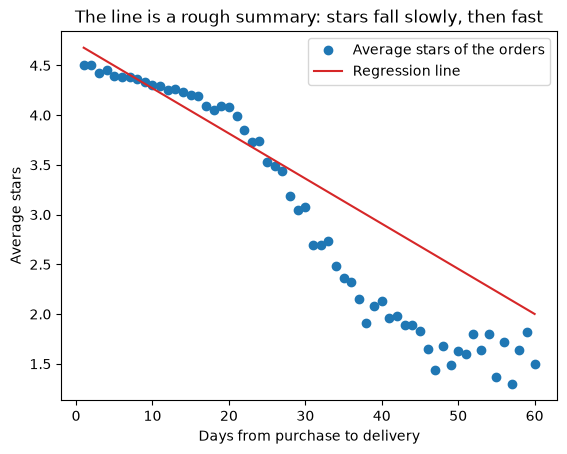

In [18]:
by_day = orders[orders["days"] < 60].groupby(orders["days"].round())["score"].mean()

ax = by_day.plot(style="o", label="Average stars of the orders")
line = model.params["Intercept"] + model.params["days"] * by_day.index
ax.plot(by_day.index, line, color="tab:red", label="Regression line")
ax.set_title("The line is a rough summary: stars fall slowly, then fast")
ax.set_xlabel("Days from purchase to delivery")
ax.set_ylabel("Average stars")
ax.legend()
ax.figure.savefig(FIGURES / "day-15-line.png", bbox_inches="tight")
plt.show()

### Step 6 — Visualizing the regression line

I grouped orders by rounded delivery days and calculated the average review score for each day. I then plotted these averages as points and added the fitted regression line in red. The visualization shows that the relationship is not perfectly linear: ratings decrease slowly at first and then fall more quickly after approximately three weeks. This demonstrates that a simple linear regression line is only a rough summary of the relationship.

In [19]:
#2.a
for day in [10, 40]:
    predicted = model.params["Intercept"] + model.params["days"] * day
    actual = by_day.loc[day] if day in by_day.index else np.nan
    print(f"{day} days: predicted={predicted:.2f}, actual={actual:.2f}")

10 days: predicted=4.27, actual=4.31
40 days: predicted=2.91, actual=2.13


### Exercise 2.a — Comparing predicted and actual ratings

I used the regression equation to predict review scores for orders delivered in 10 and 40 days. I compared these predictions with the actual average scores for the same delivery days. The differences show how accurately the linear regression model represents the observed data at these points.

## Part 3 — Hold one thing fixed: confounders

In [20]:
orders["promised"] = (orders["estimated"].dt.normalize() - orders["purchased"].dt.normalize()).dt.days
smf.ols("score ~ promised", data=orders).fit().params.round(4)

Intercept    4.3440
promised    -0.0077
dtype: float64

### Step 1 — Calculating promised delivery days

I created a new column called promised by calculating the number of days between the purchase date and the estimated delivery date. I then fitted a simple OLS regression model to examine the relationship between promised delivery days and customer review scores. The promised coefficient was -0.0077, suggesting that each additional promised day is associated with a very small decrease in the predicted review score. However, this is only an initial relationship and does not establish causation.


In [21]:
twenty = orders[orders["days"].between(19.5, 20.5)]
promise = pd.cut(twenty["promised"], [0, 20, 30, 200], right=False)
twenty.groupby(promise)["score"].agg(["size", "mean"]).round(2)

,size,mean
promised,,
"[0, 20)",100,3.02
"[20, 30)",931,4.14
"[30, 200)",733,4.15


### Step 2 — Comparing orders with similar actual delivery times

I selected orders that took approximately 20 days to arrive and grouped them by promised delivery time. Orders promised in less than 20 days had an average review score of 3.02, while orders promised between 20 and 30 days had an average score of 4.14. Orders promised between 30 and 200 days had an average score of 4.15.

This suggests that among orders with similar actual delivery times, customers gave higher ratings when the promised delivery time was longer. Orders that arrived later than promised may receive lower ratings because they did not meet customer expectations.

### Step 3 — Interpreting the relationship

The initial regression showed a small negative relationship between promised delivery days and review scores. However, when I compared orders with similar actual delivery times, the pattern changed. Orders with longer promised delivery times received higher average ratings. This suggests that customer satisfaction may depend not only on how long delivery takes, but also on whether the order arrives within the promised time. Setting realistic delivery expectations may be more important than simply promising faster delivery.

In [22]:
smf.ols("score ~ promised + days", data=orders).fit().params.round(4)

Intercept    4.4622
promised     0.0131
days        -0.0501
dtype: float64

### Step 4 — Including promised and actual delivery days

I fitted a multiple regression model using both promised delivery days and actual delivery days as predictors of review scores.

The promised coefficient changed from -0.0077 in the simple model to +0.0131 in the multiple regression model. Holding actual delivery days fixed, each additional promised day is associated with an increase of 0.0131 stars.

The actual delivery days coefficient was -0.0501. Holding promised delivery days fixed, each additional actual delivery day is associated with a decrease of 0.0501 stars.

This demonstrates how including an important variable can change the interpretation of a relationship.

### Step 5 — Understanding the confounder

A confounder is a variable that can affect the relationship between two other variables. In this example, distance could be a potential confounder because distant orders may take longer to deliver and may receive longer estimated delivery times.

The multiple regression model showed that the promised coefficient changed from negative to positive after including actual delivery days. This demonstrates how controlling for another variable can change the relationship we observe.

Distance is only a possible unobserved confounder in this analysis because it is not directly included in our dataset.

In [23]:
#3.a

late_model = smf.ols("score ~ days + late", data=orders).fit()
late_model.params.round(4)


Intercept       4.5205
late[T.True]   -1.5411
days           -0.0209
dtype: float64

### Exercise 3.a — Including late status in the regression

I fitted a multiple regression model using actual delivery days and late delivery status to explain customer review scores.

The coefficient for `days` was -0.0209, meaning that each additional actual delivery day was associated with a decrease of 0.0209 stars, holding late status constant.

The coefficient for `late[T.True]` was -1.5411, meaning that late orders were associated with 1.5411 fewer stars than orders that were not late, holding actual delivery days constant.

This suggests that arriving later than the estimated delivery date has a strong negative association with customer satisfaction.

In [24]:

northeast = ["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"]
southeast = ["ES", "MG", "RJ", "SP"]

two = orders[orders["state"].isin(northeast + southeast)].copy()

two["region"] = np.where(
    two["state"].isin(northeast),
    "Northeast",
    "Southeast"
)

two.groupby("region")["score"].mean().round(2)


region
Northeast    3.97
Southeast    4.18
Name: score, dtype: float64

### Step 1 — Comparing Northeast and Southeast

I selected orders from the Northeast and Southeast regions and created a new column called `region` to identify each order's region.

I then calculated the average review score for each region. The Northeast had an average score of 3.97, while the Southeast had an average score of 4.18.

At first, this suggests that customers in the Southeast gave higher ratings. However, this overall comparison does not account for differences in delivery times between the two regions.

In [25]:

two["wait"] = pd.cut(
    two["days"],
    [0, 7, 14, 21, 30, 300],
    right=False
)

table = two.pivot_table(
    index="wait",
    columns="region",
    values="score",
    aggfunc="mean"
).round(2)

table


region,Northeast,Southeast
wait,,
"[0, 7)",4.44,4.41
"[7, 14)",4.34,4.29
"[14, 21)",4.23,4.06
"[21, 30)",3.94,3.26
"[30, 300)",2.45,1.97


### Step 2 — Comparing regions within delivery-time groups

I divided orders into five groups based on their actual delivery times and calculated the average review score for each region within each group.

The Northeast had a higher average score than the Southeast in all five delivery-time groups, even though its overall average score was lower.

This reveals that the overall comparison can be misleading. We need to examine how orders are distributed across delivery-time groups to understand why the regional averages differ.

In [26]:

pd.crosstab(
    two["wait"],
    two["region"],
    normalize="columns"
).round(2)


region,Northeast,Southeast
wait,,
"[0, 7)",0.03,0.36
"[7, 14)",0.29,0.42
"[14, 21)",0.33,0.14
"[21, 30)",0.21,0.05
"[30, 300)",0.13,0.03


### Step 3 — Comparing the distribution of delivery times

I used a cross-tabulation with column normalization to compare the distribution of delivery times in each region.

Only 32% of Northeast orders were delivered in less than 14 days, compared with 78% of Southeast orders. In addition, 34% of Northeast orders took 21 days or more, compared with only 8% of Southeast orders.

This explains why the Northeast had a lower overall average score. It had a much larger share of slow deliveries, which generally received lower ratings.

The difference in overall regional averages is therefore strongly influenced by the distribution of delivery times, rather than showing that Northeast customers are harder to satisfy.

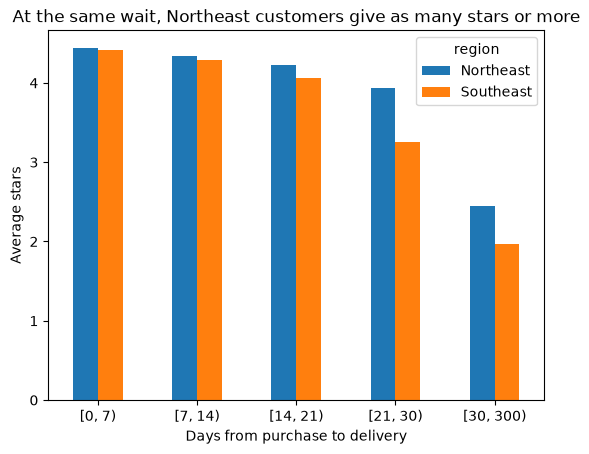

In [27]:

ax = table.plot(kind="bar", rot=0)

ax.set_title("At the same wait, Northeast customers give as many stars or more")
ax.set_xlabel("Days from purchase to delivery")
ax.set_ylabel("Average stars")

ax.figure.savefig(FIGURES / "day-15-regions.png", bbox_inches="tight")

plt.show()


### Step 4 — Visualizing the regional comparison

I created a grouped bar chart to compare the average review scores of the Northeast and Southeast across delivery-time groups.

The chart shows that the Northeast had an equal or higher average score in every delivery-time group. However, its overall average was lower because a larger proportion of its orders took longer to deliver.

I saved the chart as `day-15-regions.png` for use in the final report.

In [28]:
#4.a

north = ["AC", "AP", "AM", "PA", "RO", "RR", "TO"]

three_regions = orders[orders["state"].isin(north + southeast)].copy()

three_regions["region"] = np.where(
    three_regions["state"].isin(north),
    "North",
    "Southeast"
)

three_regions["wait"] = pd.cut(
    three_regions["days"],
    [0, 7, 14, 21, 30, 300],
    right=False
)

comparison = three_regions.pivot_table(
    index="wait",
    columns="region",
    values="score",
    aggfunc="mean"
).round(2)

north_counts = three_regions[
    three_regions["region"] == "North"
].groupby("wait").size()

comparison["North orders"] = north_counts

comparison


region,North,Southeast,North orders
wait,,,
"[0, 7)",4.22,4.41,23
"[7, 14)",4.42,4.29,360
"[14, 21)",4.30,4.06,569
"[21, 30)",4.05,3.26,488
"[30, 300)",3.13,1.97,339


### Exercise 4.a — Comparing North with Southeast

I compared the average review scores of the North and Southeast regions within the same delivery-time groups.

The North had a higher average score in four out of five groups. The Southeast had a higher score only in the shortest delivery-time group, where the North had just 23 orders.

The number of North orders varied across groups, ranging from 23 to 569 orders. This is important because averages based on small groups may be less reliable.

The results show that the regional comparison does not reverse in every delivery-time group. Therefore, the pattern observed in the Northeast comparison does not apply identically to every regional comparison.

## Part 5 — Regression to the mean

In [29]:

reviews = query("""
    SELECT
        i.seller_id,
        r.review_id,
        MIN(r.review_score) AS score,
        CASE
            WHEN MIN(o.order_purchase_timestamp) < '2017-07-01'
            THEN 'first'
            ELSE 'second'
        END AS half
    FROM clean.order_items AS i
    JOIN clean.order_reviews AS r ON r.order_id = i.order_id
    JOIN clean.orders AS o ON o.order_id = i.order_id
    WHERE o.order_purchase_timestamp >= '2017-01-01'
      AND o.order_purchase_timestamp < '2018-01-01'
    GROUP BY i.seller_id, r.review_id
""")

len(reviews)


44903

### Step 1 — Preparing seller review data

I queried the database to collect seller reviews from 2017. I joined the order items, order reviews, and orders tables using `order_id`.

I grouped the data by seller and review, then assigned each review to either the first half or the second half of 2017 based on the order purchase date.

The resulting dataset contained 44,903 rows, representing seller-review records for the analysis.

In [30]:

stars = reviews.pivot_table(
    index="seller_id",
    columns="half",
    values="score",
    aggfunc="mean"
)

counts = reviews.pivot_table(
    index="seller_id",
    columns="half",
    values="score",
    aggfunc="count"
)

both = stars[
    (counts["first"] >= 20) &
    (counts["second"] >= 20)
]

len(both)


143

### Step 2 — Keeping sellers with enough reviews

I created two pivot tables. The first calculated each seller's average review score in each half of 2017, while the second counted the number of reviews in each period.

I then kept only sellers who had at least 20 reviews in both halves of the year. This helps make the comparison more reliable by excluding sellers with too few reviews.

The final dataset contained 143 sellers.

In [31]:
worst = both.nsmallest(20, "first")
best = both.nlargest(20, "first")

pd.DataFrame({
    "worst 20": worst.mean(),
    "best 20": best.mean(),
    "all": both.mean()
}).round(2)


,worst 20,best 20,all
half,,,
first,3.71,4.57,4.18
second,3.93,4.27,4.15


### Step 3 — Selecting the worst and best sellers

I selected the 20 sellers with the lowest average review scores in the first half of 2017 and the 20 sellers with the highest scores.

The worst 20 sellers increased their average score from 3.71 to 3.93, while the best 20 sellers decreased from 4.57 to 4.27. The overall average remained almost unchanged, moving from 4.18 to 4.15.

Both extreme groups moved closer to the overall average, which is an example of regression to the mean.

### Step 4 — Interpreting the results

The worst 20 sellers improved their average score from 3.71 to 3.93, while the best 20 sellers declined from 4.57 to 4.27. The overall average stayed almost unchanged.

Both extreme groups moved closer to the overall average. This is consistent with regression to the mean: unusually low or high results tend to become less extreme when measured again.

We cannot conclude that the fictional warning letter caused the improvement. The observed change may partly be explained by natural variation and regression to the mean.

In [32]:
#5.a
both_10 = stars[
    (counts["first"] >= 10) &
    (counts["second"] >= 10)
]

worst_10 = both_10.nsmallest(20, "first")
best_10 = both_10.nlargest(20, "first")

pd.DataFrame({
    "worst 20": worst_10.mean(),
    "best 20": best_10.mean(),
    "all": both_10.mean()
}).round(2)

,worst 20,best 20,all
half,,,
first,3.42,4.68,4.15
second,3.97,4.25,4.12


### Exercise 5.a — Results and interpretation

After reducing the minimum review requirement from 20 to 10 reviews per half, the worst 20 sellers increased their average score from 3.42 to 3.97, an improvement of 0.55 points.

The best 20 sellers decreased from 4.68 to 4.25, while the overall average remained almost unchanged, moving from 4.15 to 4.12.

Compared with the 20-review requirement, both extreme groups moved further toward the overall average. Sellers with fewer reviews may have averages that are more affected by random variation, making regression to the mean more noticeable.

However, this comparison does not prove that the review count alone caused the larger change, because the eligible seller groups also changed.